In [15]:
import os, re, csv, glob, random, subprocess, tempfile, json, string, difflib
from scipy import ndimage
from collections import Counter, defaultdict
from datetime import datetime
from PIL import Image, ImageFilter, ImageOps
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt

In [16]:
FOLDER = "/Users/varunmatta/Drive/Varun/Projects/captcha_tester/training/data/varun"
OCR = "/Users/varunmatta/Drive/Varun/Projects/captcha_tester/host/ocr"   # Apple Vision, accurate mode
LOG = "/Users/varunmatta/Drive/Varun/Projects/captcha_tester/data/ocr_review.json"   # your reviews + confusions
ROUNDS = "/Users/varunmatta/Drive/Varun/Projects/captcha_tester/data/rounds"   # older labeled rounds (label vs raw OCR)

PARAMS = dict(
    LETTER_MAX=35,  # pixel <= this counts as letter (dark gray, not pure black)
    LEVEL_TOL=6,    # pixel within this of its line's gray counts as line core
    WIN=3,          # half-size of window used to find the local line gray
    MAX_GAP=2,      # widest line cut (px) bridged inside a letter
    SCALE=2,        # upscale factor before OCR
    THICKEN=3,      # MinFilter size that fattens strokes (odd, 1 = off)
    BLUR=1.5,       # Gaussian blur radius (0 = off)
    LINE_MIN=30,    # darkest gray allowed when estimating a line's gray
    BG_MIN=250,     # pixel >= this counts as background
    BORDER=40,      # white border added around the output
    CLOSE=0,        # radius of mask closing (0 = off)
    MIN_BLOB=0,     # drop connected blobs smaller than this many pixels (0 = off)
)
DIRS = [(0, 1), (1, 0), (1, 1), (1, -1)]

In [17]:
# 1. pick
def pick_image():
    """Random existing image path (file numbers have gaps, so retry until one exists)."""
    while True:
        path = os.path.join(FOLDER, f"{random.randint(1, 125790)}.png")
        if os.path.exists(path):
            return path

In [18]:
# 2. load
def load(path):
    """Image file -> grayscale uint8 numpy array, shape (h, w)."""
    return np.array(Image.open(path).convert("L"))

In [19]:
# walk from (y, x) in one direction over line-core pixels (state 1)
# returns (steps taken, state of the pixel that ended the walk)
# if the run is longer than max_gap it gives up and returns (n, 1)
def _walk(state, y, x, dy, dx, max_gap):
    h, w = state.shape
    n = 0
    while True:
        y = y + dy
        x = x + dx
        if not (0 <= y < h and 0 <= x < w):
            return n, 0
        if state[y, x] != 1:
            return n, state[y, x]
        n = n + 1
        if n > max_gap:
            return n, 1

# stage 1: find the masks (slow part)
def find_masks(a, **overrides):
    p = dict(PARAMS)
    p.update(overrides)
    a = a.astype(int)
    letters = a <= p["LETTER_MAX"]
    noise = (a > p["LETTER_MAX"]) & (a < p["BG_MIN"])
    r = p["WIN"]

    # for each noise pixel, the most common gray in its window = gray of the line through it
    level = np.zeros_like(a)
    for y, x in zip(*np.where(noise)):
        win = a[max(0, y - r):y + r + 1, max(0, x - r):x + r + 1]
        vals = win[(win > p["LINE_MIN"]) & (win < p["BG_MIN"])]
        if vals.size:
            v, c = np.unique(vals, return_counts=True)
            level[y, x] = v[np.argmax(c)]
    core = noise & (np.abs(a - level) <= p["LEVEL_TOL"])

    # 0 = background, 1 = line core, 2 = letter
    state = np.zeros_like(a)
    state[core] = 1
    state[letters] = 2

    # line core pixel whose shortest run is <= MAX_GAP with letter at both ends = a cut, fill it
    fill = np.zeros_like(core)
    for y, x in zip(*np.where(core)):
        best = None
        for dy, dx in DIRS:
            n1, e1 = _walk(state, y, x, dy, dx, p["MAX_GAP"])
            n2, e2 = _walk(state, y, x, -dy, -dx, p["MAX_GAP"])
            span = n1 + n2 + 1
            if best is None or span < best[0]:
                best = (span, e1, e2)
        if best[0] <= p["MAX_GAP"] and best[1] == 2 and best[2] == 2:
            fill[y, x] = True
    return letters, core, fill

# stage 2: heal small breaks, drop tiny specks (both off by default)
def tidy(mask, **overrides):
    p = dict(PARAMS)
    p.update(overrides)
    if p["CLOSE"] > 0:
        size = 2 * p["CLOSE"] + 1
        mask = ndimage.binary_closing(mask, structure=np.ones((size, size), dtype=bool))
    if p["MIN_BLOB"] > 0:
        labeled, count = ndimage.label(mask, structure=np.ones((3, 3)))
        keep = np.zeros(count + 1, dtype=bool)
        for k in range(1, count + 1):
            if (labeled == k).sum() >= p["MIN_BLOB"]:
                keep[k] = True
        mask = keep[labeled]
    return mask

# stage 3: boolean letter mask -> final image (upscale, thicken, blur, border)
def render(mask, **overrides):
    p = dict(PARAMS)
    p.update(overrides)
    im = Image.fromarray(np.where(mask, 0, 255).astype(np.uint8))
    im = im.resize((im.width * p["SCALE"], im.height * p["SCALE"]), Image.LANCZOS)
    if p["THICKEN"] > 1:
        im = im.filter(ImageFilter.MinFilter(p["THICKEN"]))
    if p["BLUR"]:
        im = im.filter(ImageFilter.GaussianBlur(p["BLUR"]))
    im = ImageOps.expand(im, border=p["BORDER"], fill=255)
    return np.array(im)

# same job and signature as your old clean(), so run(), score() and sweep() still work
# output is upscaled, thickened and bordered, so it is not the same size as the input
def clean(a, **overrides):
    letters, core, fill = find_masks(a, **overrides)
    return render(tidy(letters | fill, **overrides), **overrides)

In [20]:
# 4. OCR
def ocr_many(images):
    """Cleaned image arrays -> raw texts, one OCR call for all (much faster than one call each)."""
    with tempfile.TemporaryDirectory() as tmp:
        paths = [os.path.join(tmp, f"{i}.png") for i in range(len(images))]
        for c, p in zip(images, paths):
            Image.fromarray(c).save(p)
        out = subprocess.run([OCR] + paths, capture_output=True, text=True, check=True).stdout
    got = dict(line.split("\t", 1) for line in out.splitlines())
    return [got.get(p, "").strip() for p in paths]

def ocr(c):
    """Cleaned image array -> raw text Apple Vision reads."""
    return ocr_many([c])[0]

# Vision has no character whitelist and sometimes returns symbols, Cyrillic/Greek lookalikes, or
# letters the captcha never uses (I, 1, 0, O, ...). Any OCR character outside the captcha alphabet is
# certainly wrong, so map it to the true character it most often stood for in labeled data
# (old rounds + your reviews). Confusions between two real captcha characters (e.g. 9 vs q) can't be
# fixed by a map - those need better cleaning.
HOMOGLYPHS = dict(zip(   # fallback for lookalikes not seen in labeled data yet
    "АВЕЗКМНОРСТУХЅІЈЬаеіјорсухԁһԛѕзбΑΒΕΖΗΙΚΜΝΟΡΤΥΧαοιν",
    "ABE3KMHOPCTyXSIJbaeijopcyxdhqs36ABEZHIKMNOPTYXaoiv"))
LENGTH = 5

def labeled_pairs():
    """(truth, raw OCR) from the old labeled rounds and from your reviews."""
    for f in glob.glob(os.path.join(ROUNDS, "r*", "results.csv")):
        with open(f) as fh:
            yield from ((r["label"], r["raw"]) for r in csv.DictReader(fh) if r["label"])
    if os.path.exists(LOG):
        with open(LOG) as fh:
            yield from ((r["truth"], r["raw"]) for r in json.load(fh)["reviews"].values())

def learn_map():
    """OCR char outside the captcha alphabet -> true char it most often stood for."""
    pairs = list(labeled_pairs())
    alphabet = set("".join(t for t, _ in pairs))
    votes = defaultdict(Counter)
    for truth, raw in pairs:
        if len(truth) == len(raw):   # only aligned reads say which char stood for which
            for g, t in zip(raw, truth):
                if g != t and g not in alphabet:
                    votes[g][t] += 1
    return {**HOMOGLYPHS, **{g: v.most_common(1)[0][0] for g, v in votes.items()}}

LOOKALIKE = learn_map()   # re-learned before each batch, so new reviews count

def restrict(text):
    """Raw OCR -> only English letters/digits, at most 5."""
    text = "".join(LOOKALIKE.get(ch, ch) for ch in text)
    return re.sub(r"[^A-Za-z0-9]", "", text)[:LENGTH]

In [21]:
# 5. show
def show(a, c, title):
    """Original and cleaned side by side."""
    fig, ax = plt.subplots(1, 2, figsize=(12, 3))
    ax[0].imshow(a, cmap="gray", vmin=0, vmax=255)
    ax[1].imshow(c, cmap="gray", vmin=0, vmax=255)
    for x in ax: x.axis("off")
    fig.suptitle(title)
    plt.show()
    
# original | cleaned side by side. path=None picks a random image. returns the path
# steps=True also shows the intermediate masks
def compare(path=None, steps=False, **overrides):
    path = path or pick_image()
    a = load(path)
    letters, core, fill = find_masks(a, **overrides)
    c = render(tidy(letters | fill, **overrides), **overrides)

    panels = list()
    panels.append(("original", a))
    if steps:
        panels.append(("letters only", np.where(letters, 0, 255)))
        panels.append(("line cores", np.where(core, 0, 255)))
        panels.append(("filled cuts", np.where(fill, 0, 255)))
    panels.append(("cleaned", c))

    fig, ax = plt.subplots(1, len(panels), figsize=(4 * len(panels), 2.5))
    ax = np.atleast_1d(ax)
    for axis, (title, img) in zip(ax, panels):
        axis.imshow(img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        axis.set_title(title)
        axis.axis("off")
    fig.suptitle(os.path.basename(path) + "   " + str(overrides))
    plt.show()
    return path

# one image, one setting varied, one cleaned version per value
def tune(name, values, path=None, **overrides):
    path = path or pick_image()
    a = load(path)
    fig, ax = plt.subplots(len(values) + 1, 1, figsize=(5, 1.6 * (len(values) + 1)))
    ax[0].imshow(a, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax[0].set_title("original " + os.path.basename(path))
    ax[0].axis("off")
    for i, v in enumerate(values):
        settings = dict(overrides)
        settings[name] = v
        ax[i + 1].imshow(clean(a, **settings), cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        ax[i + 1].set_title(name + " = " + str(v))
        ax[i + 1].axis("off")
    plt.tight_layout()
    plt.show()
    return path

# n random images, original next to cleaned
def grid(n=8, cols=2, **overrides):
    paths = list()
    for i in range(n):
        paths.append(pick_image())
    rows = (n + cols - 1) // cols
    fig, ax = plt.subplots(rows, cols * 2, figsize=(5 * cols, 1.5 * rows))
    ax = np.array(ax).reshape(rows, cols * 2)
    for i, path in enumerate(paths):
        r = i // cols
        c = (i % cols) * 2
        a = load(path)
        ax[r][c].imshow(a, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        ax[r][c + 1].imshow(clean(a, **overrides), cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        ax[r][c].set_title(os.path.basename(path), fontsize=8)
    for axis in ax.flatten():
        axis.axis("off")
    plt.tight_layout()
    plt.show()
    return paths

In [22]:
# entry point
def run(path=None):
    """pick -> load -> clean -> OCR -> restrict -> show. Pass a path to read a specific image.
    Returns (path, raw OCR, final text)."""
    path = path or pick_image()
    a = load(path)
    c = clean(a)
    raw = ocr(c)
    text = restrict(raw)
    show(a, c, f"{os.path.basename(path)}  ->  {text}")
    print(path, "->", text, f"(OCR said {raw})" if raw != text else "")
    return path, raw, text

In [23]:
# 6. review log: your corrections -> which characters OCR confuses, and on which images
CHARS = string.ascii_lowercase + string.ascii_uppercase + string.digits

def load_log():
    if os.path.exists(LOG):
        with open(LOG) as f:
            return json.load(f)
    return {"reviews": {}}

def diff(truth, got):
    """Align truth vs OCR. Returns (wrong, extra):
    wrong = [(pos in truth, true char, what OCR gave; '' if dropped)], extra = chars OCR added."""
    if len(truth) == len(got):   # same length: compare position by position
        return [(i, t, g) for i, (t, g) in enumerate(zip(truth, got)) if t != g], []
    wrong, extra = [], []
    for op, i1, i2, j1, j2 in difflib.SequenceMatcher(None, truth, got, autojunk=False).get_opcodes():
        t, g = truth[i1:i2], got[j1:j2]
        if op == "insert":
            extra.append(g)
        elif op == "delete":
            wrong += [(i1 + k, ch, "") for k, ch in enumerate(t)]
        elif op == "replace":
            # same length: char for char; uneven (e.g. 'm' read as 'rn'): each true char gets the whole span
            wrong += [(i1 + k, ch, g[k] if len(t) == len(g) else g) for k, ch in enumerate(t)]
    return wrong, extra

def summarize(reviews):
    """Rebuild per-character confusion table from all reviews (reviews are the source of truth)."""
    new = lambda: {"seen": 0, "wrong": 0, "as": {}}
    conf = {ch: new() for ch in CHARS}
    extra = []
    for img, r in reviews.items():
        for ch in r["truth"]:
            conf.setdefault(ch, new())["seen"] += 1
        wrong, added = diff(r["truth"], r["got"])
        for pos, t, g in wrong:
            c = conf.setdefault(t, new())
            c["wrong"] += 1
            c["as"].setdefault(g or "(missing)", []).append(
                {"image": img, "pos": pos, "truth": r["truth"], "got": r["got"], "time": r["time"]})
        extra += [{"image": img, "added": g, "truth": r["truth"], "got": r["got"], "time": r["time"]} for g in added]
    seen = sum(c["seen"] for c in conf.values())
    wrong = sum(c["wrong"] for c in conf.values())
    pairs = sorted(((t, g, len(ev)) for t, c in conf.items() for g, ev in c["as"].items()), key=lambda x: -x[2])
    summary = {"images": len(reviews),
               "exact": sum(r["correct"] for r in reviews.values()),
               "chars": seen, "chars_wrong": wrong,
               "top_confusions": [f"{t} -> {g} x{n}" for t, g, n in pairs]}
    return conf, extra, summary

def save_log(log):
    log["confusions"], log["extra"], log["summary"] = summarize(log["reviews"])
    with open(LOG, "w") as f:
        json.dump(log, f, indent=1, ensure_ascii=False)

def review(batch):
    """Ask about each (path, raw, text) in batch. Enter = OCR right, type the true text if wrong, s = skip, q = stop."""
    log = load_log()
    for i, (path, raw, got) in enumerate(batch, 1):
        img = os.path.splitext(os.path.basename(path))[0]
        plt.figure(figsize=(4, 1.5)); plt.imshow(load(path), cmap="gray", vmin=0, vmax=255); plt.axis("off"); plt.show()
        while True:
            ans = input(f"[{i}/{len(batch)}] {img}.png  OCR: {got}{f'  (raw {raw})' if raw != got else ''}   Enter=correct / type true text / s=skip / q=quit: ").strip()
            if ans in ("", "s", "q") or re.fullmatch(f"[A-Za-z0-9]{{{LENGTH}}}", ans):
                break
            print(f"  captchas are {LENGTH} English letters/digits, try again")
        if ans == "q":
            break
        if ans == "s":
            continue
        truth = ans or got
        log["reviews"][img] = {"got": got, "raw": raw, "truth": truth, "correct": got == truth,
                               "time": datetime.now().isoformat(timespec="seconds"),
                               "params": dict(PARAMS)}
        if truth != got:
            wrong, added = diff(truth, got)
            print("  wrong:", ", ".join(f"{t} -> {g or '(missing)'} @{p}" for p, t, g in wrong), f"added: {added}" if added else "")
        save_log(log)   # save every answer so nothing is lost on quit
    s = load_log().get("summary")
    if s:
        print(f"\nreviewed {s['images']}  exact {s['exact']}/{s['images']}  chars wrong {s['chars_wrong']}/{s['chars']}")
        print("top confusions:", s["top_confusions"][:10])

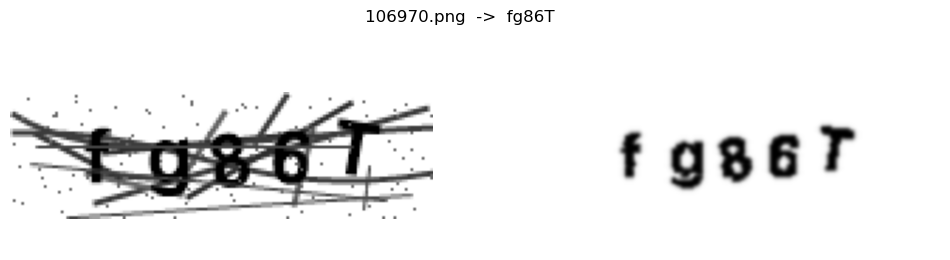

/Users/varunmatta/Downloads/image_ftech_solver/varun/106970.png -> fg86T 


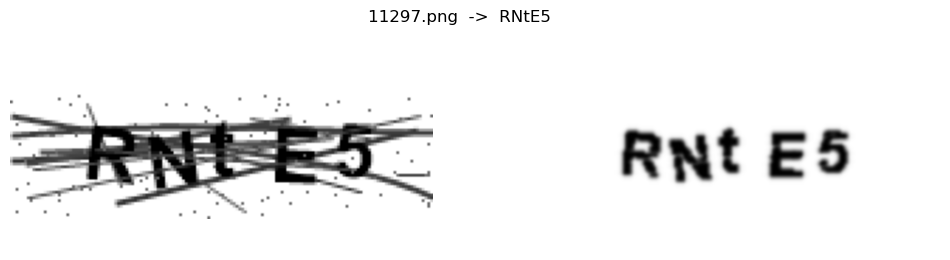

/Users/varunmatta/Downloads/image_ftech_solver/varun/11297.png -> RNtE5 


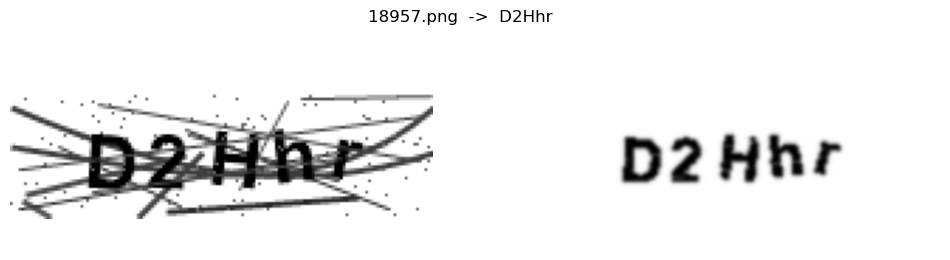

/Users/varunmatta/Downloads/image_ftech_solver/varun/18957.png -> D2Hhr 


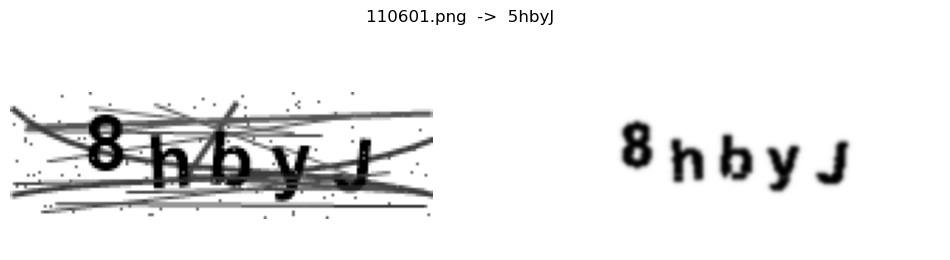

/Users/varunmatta/Downloads/image_ftech_solver/varun/110601.png -> 5hbyJ (OCR said ShbyJ)


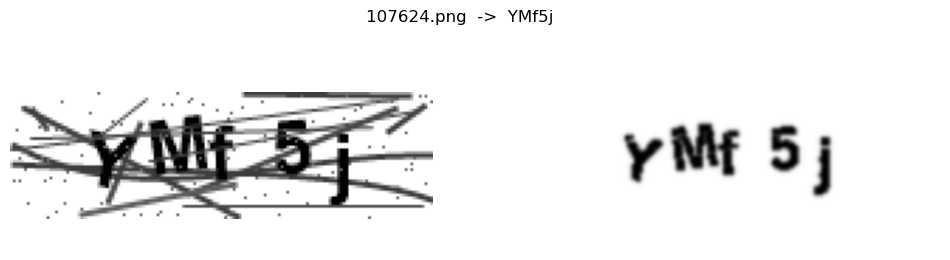

/Users/varunmatta/Downloads/image_ftech_solver/varun/107624.png -> YMf5j 


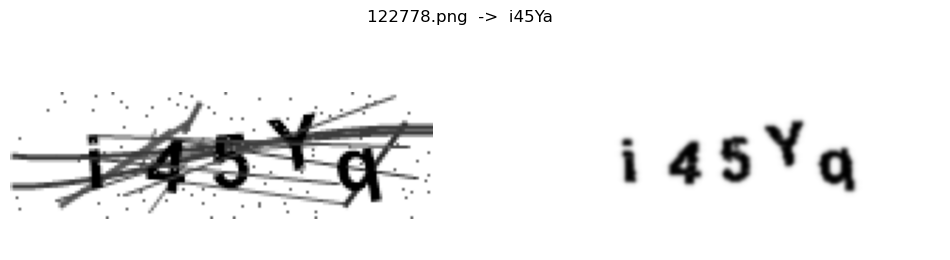

/Users/varunmatta/Downloads/image_ftech_solver/varun/122778.png -> i45Ya (OCR said ¡45Ya)


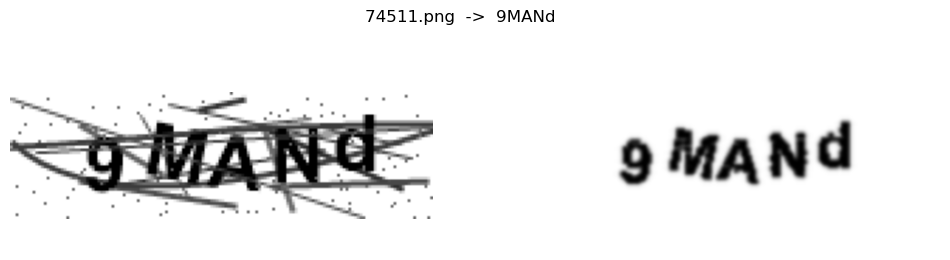

/Users/varunmatta/Downloads/image_ftech_solver/varun/74511.png -> 9MANd 


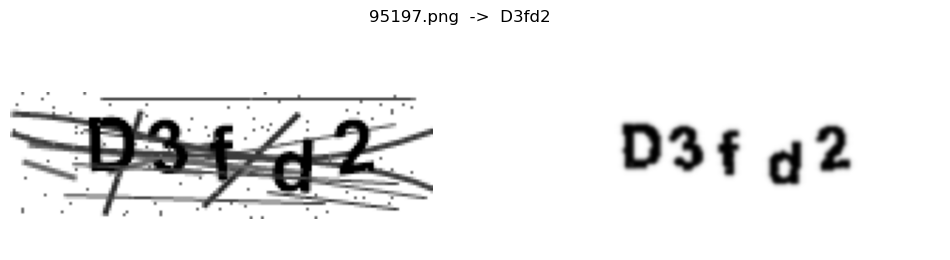

/Users/varunmatta/Downloads/image_ftech_solver/varun/95197.png -> D3fd2 


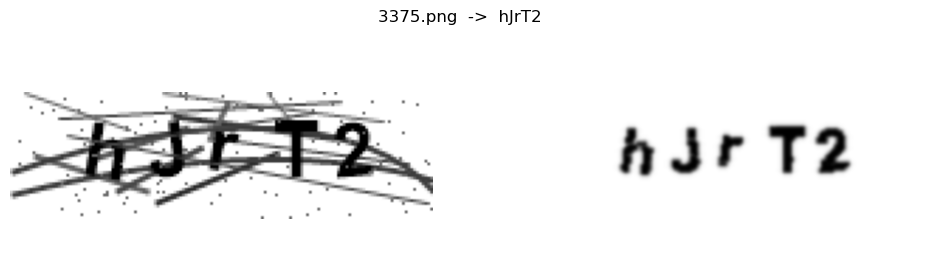

/Users/varunmatta/Downloads/image_ftech_solver/varun/3375.png -> hJrT2 


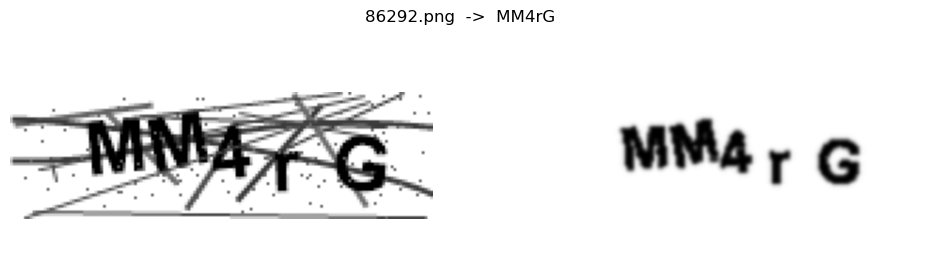

/Users/varunmatta/Downloads/image_ftech_solver/varun/86292.png -> MM4rG 


In [24]:
# batch of 10 -> review
LOOKALIKE = learn_map()   # pick up corrections from earlier reviews
batch = [run() for _ in range(10)]
#review(batch)

In [25]:
# 7. parameter sweep on your reviewed images: change one setting at a time, keep the rest at PARAMS
def reviewed():
    """[(image array, true text)] for every image you've reviewed."""
    return [(load(os.path.join(FOLDER, f"{img}.png")), r["truth"]) for img, r in load_log()["reviews"].items()]

def score(data, **overrides):
    """Full pipeline (clean -> OCR -> restrict) on data -> (exact matches, characters right)."""
    preds = [restrict(t) for t in ocr_many([clean(a, **overrides) for a, _ in data])]
    exact = sum(p == t for p, (_, t) in zip(preds, data))
    chars = sum(x == y for p, (_, t) in zip(preds, data) for x, y in zip(p, t))
    return exact, chars

def sweep(grid, data=None):
    """Score every value in grid, one setting at a time; print a table and plot exact matches per setting."""
    data = data or reviewed()
    n = len(data)
    base = score(data)
    print(f"{n} reviewed images   current PARAMS: exact {base[0]}/{n}  chars {base[1]}/{LENGTH * n}\n")
    results = {}
    for name, values in grid.items():
        results[name] = []
        for v in values:
            ex, ch = base if v == PARAMS[name] else score(data, **{name: v})
            results[name].append(ex)
            mark = "   <- current" if v == PARAMS[name] else ""
            print(f"{name:>10} = {v:<4}  exact {ex:>3}/{n} ({ex - base[0]:+d})  chars {ch}/{LENGTH * n}{mark}")
        print()
    fig, axes = plt.subplots(1, len(grid), figsize=(3.2 * len(grid), 2.8), sharey=True)
    for ax, (name, values) in zip(np.atleast_1d(axes), grid.items()):
        ax.plot(range(len(values)), results[name], "o-")
        ax.axhline(base[0], color="gray", ls=":")
        ax.set_xticks(range(len(values)), [str(v) for v in values])
        ax.set_title(name)
    np.atleast_1d(axes)[0].set_ylabel(f"exact / {n}")
    plt.tight_layout(); plt.show()
    return results

In [26]:
# reviewed images -> list of (image name, image array, true text)
def labeled_data():
    data = list()
    for img, r in load_log()["reviews"].items():
        data.append((img, load(os.path.join(FOLDER, img + ".png")), r["truth"]))
    return data

# settings that change the mask (slow step). the rest only change rendering (fast step)
MASK_KEYS = ["LETTER_MAX", "LEVEL_TOL", "WIN", "MAX_GAP", "LINE_MIN", "BG_MIN"]
_cache = dict()

# find_masks is slow, so remember its result per (image, mask settings)
def get_mask(name, a, settings):
    key = [name]
    for k in MASK_KEYS:
        key.append(settings[k])
    key = tuple(key)
    if key not in _cache:
        letters, core, fill = find_masks(a, **settings)
        _cache[key] = letters | fill
    return _cache[key]

# one config -> (images read exactly right, characters right). higher is better
def score_config(data, settings):
    images = list()
    for name, a, truth in data:
        mask = get_mask(name, a, settings)
        images.append(render(tidy(mask, **settings), **settings))
    raws = ocr_many(images)
    exact = 0
    chars = 0
    for raw, (name, a, truth) in zip(raws, data):
        pred = restrict(raw)
        if pred == truth:
            exact = exact + 1
        for x, y in zip(pred, truth):
            if x == y:
                chars = chars + 1
    return (exact, chars)

# try every value of one setting at a time, keep improvements, repeat for `rounds`
def search(grid, rounds=2, test_frac=0.3):
    data = labeled_data()
    random.shuffle(data)
    cut = int(len(data) * (1 - test_frac))
    train = data[:cut]
    test = data[cut:]
    print(str(len(train)) + " train images, " + str(len(test)) + " held-out images")

    best = dict(PARAMS)
    best_score = score_config(train, best)
    print("start: train", best_score, "test", score_config(test, best))

    history = list()
    for r in range(rounds):
        changed = False
        for name, values in grid.items():
            for v in values:
                if v == best[name]:
                    continue
                trial = dict(best)
                trial[name] = v
                s = score_config(train, trial)
                history.append((name, v, s))
                if s > best_score:      # ties keep the current value
                    best = trial
                    best_score = s
                    changed = True
                    print("round " + str(r + 1) + ": " + name + " = " + str(v) + " -> train " + str(s))
        if not changed:
            break

    print("\nbest config:", best)
    print("train", best_score, "test", score_config(test, best))
    print("default on test:", score_config(test, dict(PARAMS)))
    return best, history

# every reviewed image the pipeline still gets wrong
def failures(data, settings):
    images = list()
    for name, a, truth in data:
        mask = get_mask(name, a, settings)
        images.append(render(tidy(mask, **settings), **settings))
    raws = ocr_many(images)
    bad = list()
    for raw, (name, a, truth) in zip(raws, data):
        pred = restrict(raw)
        if pred != truth:
            bad.append((name, truth, pred, raw))
    for b in bad:
        print(b[0], "truth", b[1], "got", b[2], "raw", b[3])
    return bad

In [27]:
GRID = dict(
    LETTER_MAX=[20, 35, 50, 70],
    MAX_GAP=[1, 2, 3, 4],
    THICKEN=[1, 3, 5],
    BLUR=[0, 1, 1.5],
    CLOSE=[0, 1, 2],
    MIN_BLOB=[0, 8, 20],
)
best, history = search(GRID)
bad = failures(labeled_data(), PARAMS)

85 train images, 37 held-out images
start: train (68, 406) test (31, 177)

best config: {'LETTER_MAX': 35, 'LEVEL_TOL': 6, 'WIN': 3, 'MAX_GAP': 2, 'SCALE': 2, 'THICKEN': 3, 'BLUR': 1.5, 'LINE_MIN': 30, 'BG_MIN': 250, 'BORDER': 40, 'CLOSE': 0, 'MIN_BLOB': 0}
train (68, 406) test (31, 177)
default on test: (31, 177)
94667 truth 4RmFj got 4RMFj raw 4RMFj
107913 truth BR2tQ got BR2fQ raw BR21Q
11186 truth j6Hj2 got i6Hi2 raw і6HI2
77838 truth QQq99 got QQ999 raw QQ999
87563 truth qGMq9 got 9GM99 raw 9GM99
61986 truth NJ2yG got NJ2YG raw NJ2YG
96046 truth gh4GH got 9h4GH raw 9h4GH
73122 truth Dm5rn got Bm5rn raw Bm5rn
33293 truth i8aYF got igaYF raw igaYF
107568 truth qL2Mt got aL2Mt raw aL2Mt
3064 truth 6DEqY got 6DEQY raw 6DEQY
9934 truth rGA6e got rGAGe raw rGAGe
80444 truth 3Q4yL got 3Q4YL raw 3Q4YL
122184 truth RYgT2 got RY9T2 raw RY9T2
81383 truth FF59a got FF5ga raw FF5ga
116631 truth Aiq62 got Ai962 raw Ai962
52224 truth Fa9ht got Faght raw Faght
51428 truth 8NYNq got 8NYNa raw 8NYN